In [46]:
import pandas as pd
import numpy as np

df = pd.read_csv("PSCompPars.csv", comment="#")


df = df.dropna(subset=["pl_eqt"])

df.info()

<class 'pandas.DataFrame'>
Index: 5911 entries, 0 to 6450
Data columns (total 84 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pl_name          5911 non-null   str    
 1   hostname         5911 non-null   str    
 2   sy_snum          5911 non-null   int64  
 3   sy_pnum          5911 non-null   int64  
 4   discoverymethod  5911 non-null   str    
 5   disc_year        5911 non-null   int64  
 6   disc_facility    5911 non-null   str    
 7   pl_controv_flag  5911 non-null   int64  
 8   pl_orbper        5841 non-null   float64
 9   pl_orbpererr1    5356 non-null   float64
 10  pl_orbpererr2    5356 non-null   float64
 11  pl_orbperlim     5841 non-null   float64
 12  pl_orbsmax       5646 non-null   float64
 13  pl_orbsmaxerr1   3727 non-null   float64
 14  pl_orbsmaxerr2   3727 non-null   float64
 15  pl_orbsmaxlim    5646 non-null   float64
 16  pl_rade          5872 non-null   float64
 17  pl_radeerr1      4310 non-null

In [47]:
#removing metadata columns
metadata_cols = [
    "hostname",
    "hd_name",
    "hip_name",
    "tic_id",
    "gaia_id",
    "pl_letter",
    "default_flag",
    "pl_controv_flag",
    "discoverymethod",
    "disc_year",
    "disc_facility",
    "disc_telescope",
    "disc_instrument",
    "pl_refname",
    "st_refname",
    "sy_refname",
    "rowupdate",
    "releasedate",
    "rastr",
    "decstr",
    "ra",
    "dec",
    "sy_dist",
    "sy_plx",
    "sy_pm"
]

metadata_to_drop = []

for col in metadata_cols:
    if col in df.columns:
        metadata_to_drop.append(col)

df.drop(columns=metadata_to_drop, inplace=True)

# removing non-numeric columns, except planet names

non_numeric_cols = []

for col in df.select_dtypes(exclude=np.number).columns:
    if col != "pl_name":
        non_numeric_cols.append(col)
        
df = df.drop(columns=non_numeric_cols)


#removing measurement uncertainty and limit columns

uncertainty_cols = []

for col in df.columns:

    col_lower = col.lower()

    if (col_lower.endswith("err1") or
        col_lower.endswith("err2") or
        col_lower.endswith("lim")):
        uncertainty_cols.append(col)

df = df.drop(columns=uncertainty_cols)


# removing columns with more than 70% missing values
missing_pct = df.isna().mean() * 100

nullval_cols = []

for col in df.columns:
    if col != "pl_eqt" and col != "pl_name":
        if missing_pct[col] > 70:
            nullval_cols.append(col)

df = df.drop(columns=sparse_cols)

print("Columns removed:", sparse_cols)
print("Remaining dataset shape:", df.shape)

df.info()

df.describe().T


Columns removed: []
Remaining dataset shape: (5911, 21)
<class 'pandas.DataFrame'>
Index: 5911 entries, 0 to 6450
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   pl_name      5911 non-null   str    
 1   sy_snum      5911 non-null   int64  
 2   sy_pnum      5911 non-null   int64  
 3   pl_orbper    5841 non-null   float64
 4   pl_orbsmax   5646 non-null   float64
 5   pl_rade      5872 non-null   float64
 6   pl_radj      5872 non-null   float64
 7   pl_bmasse    5885 non-null   float64
 8   pl_bmassj    5885 non-null   float64
 9   pl_orbeccen  5315 non-null   float64
 10  pl_insol     5849 non-null   float64
 11  pl_eqt       5911 non-null   float64
 12  ttv_flag     5911 non-null   int64  
 13  st_teff      5900 non-null   float64
 14  st_rad       5894 non-null   float64
 15  st_mass      5904 non-null   float64
 16  st_met       5561 non-null   float64
 17  st_logg      5885 non-null   float64
 18  sy_vmag 

,count,mean,std,min,25%,50%,75%,max
sy_snum,5911.0,1.103367,3.421449e-01,1.000000,1.000000,1.000000,1.000000,4.000000e+00
sy_pnum,5911.0,1.783285,1.161814e+00,1.000000,1.000000,1.000000,2.000000,8.000000e+00
pl_orbper,5841.0,72965.966769,5.262373e+06,0.176891,4.301219,10.687576,38.060000,4.020000e+08
pl_orbsmax,5646.0,12.442723,2.487635e+02,0.005000,0.051000,0.095340,0.240528,1.200000e+04
pl_rade,5872.0,5.697182,5.395723e+00,0.309800,1.820000,2.790000,11.309881,8.720587e+01
pl_radj,5872.0,0.508297,4.814079e-01,0.027639,0.162370,0.249000,1.009000,7.780000e+00
pl_bmasse,5885.0,376.325627,1.091024e+03,0.037400,4.200000,8.910000,169.000000,1.265150e+04
pl_bmassj,5885.0,1.184190,3.433084e+00,0.000118,0.013215,0.028003,0.530000,3.980607e+01
pl_orbeccen,5315.0,0.078064,1.519112e-01,0.000000,0.000000,0.000000,0.090000,9.500000e-01
pl_insol,5849.0,532.424970,9.867982e+03,0.000000,10.183800,66.876600,284.211000,6.363521e+05


In [48]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": df.isna().mean() * 100
})

display(
    missing_summary
    .sort_values("Missing Percentage", ascending=False)
)

,Missing Count,Missing Percentage
pl_orbeccen,596,10.082896
st_met,350,5.921164
pl_orbsmax,265,4.483167
pl_orbper,70,1.184233
pl_insol,62,1.048892
sy_gaiamag,59,0.998139
pl_radj,39,0.659787
pl_rade,39,0.659787
sy_vmag,27,0.456776
pl_bmasse,26,0.439858


In [49]:
%pip install matplotlib

Text(0, 0.5, 'Number of Planets')

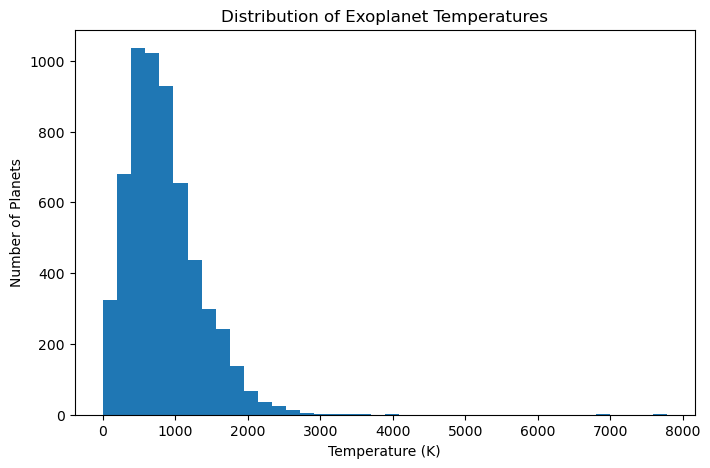

In [50]:
ax = df["pl_eqt"].plot(
    kind="hist",
    bins=40,
    figsize=(8, 5),
    title="Distribution of Exoplanet Temperatures"
)

ax.set_xlabel("Temperature (K)")
ax.set_ylabel("Number of Planets")

st_teff        0.322697
pl_insol       0.303841
st_mass        0.263913
pl_orbeccen   -0.248182
sy_kmag        0.178547
sy_pnum       -0.173867
st_logg       -0.133563
pl_radj        0.123146
pl_rade        0.123145
sy_gaiamag     0.104734
st_met         0.091452
ttv_flag      -0.085010
sy_vmag        0.074390
st_rad         0.045322
pl_bmassj     -0.029959
pl_bmasse     -0.029952
pl_orbsmax     0.015729
sy_snum        0.013790
pl_orbper     -0.007922
Name: pl_eqt, dtype: float64

<Axes: title={'center': 'Features Most Strongly Correlated with Equilibrium Temperature'}, xlabel='Correlation'>

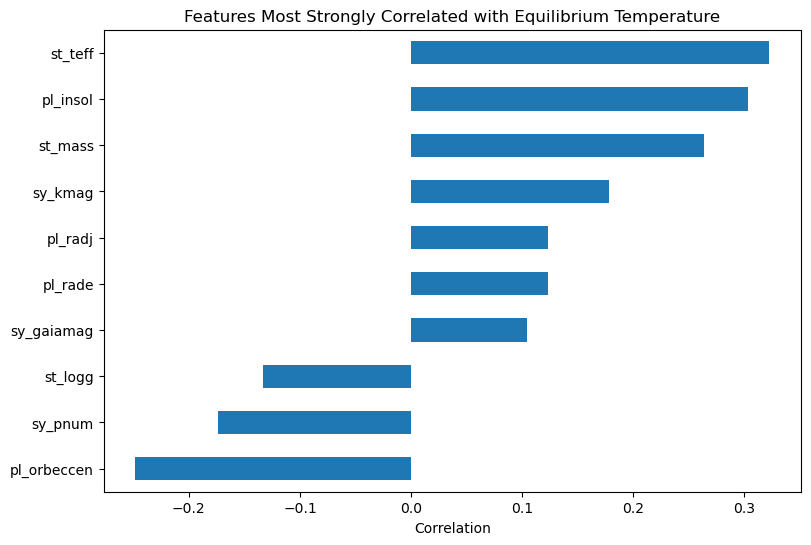

In [51]:
# finding which numerical features have the strongest correlation with temperature
correlations = df.select_dtypes(include=np.number).corr()
target_corr = correlations["pl_eqt"].drop("pl_eqt").dropna()
target_corr = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)

display(target_corr)

target_corr.head(10).sort_values().plot(
    kind="barh",
    title="Features Most Strongly Correlated with Equilibrium Temperature",
    xlabel="Correlation",
    figsize=(9, 6)
)


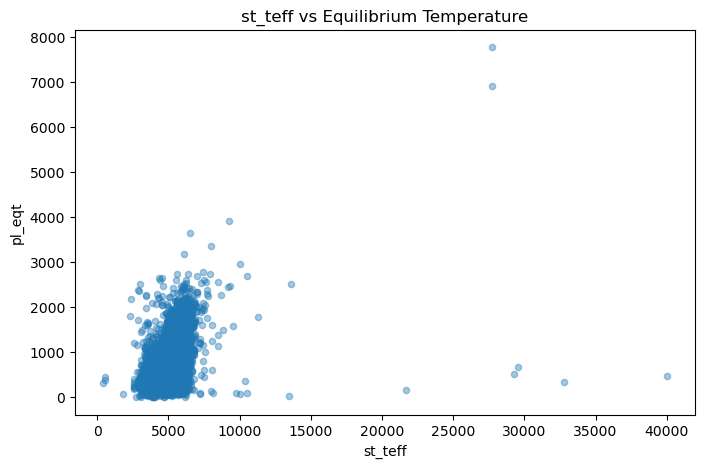

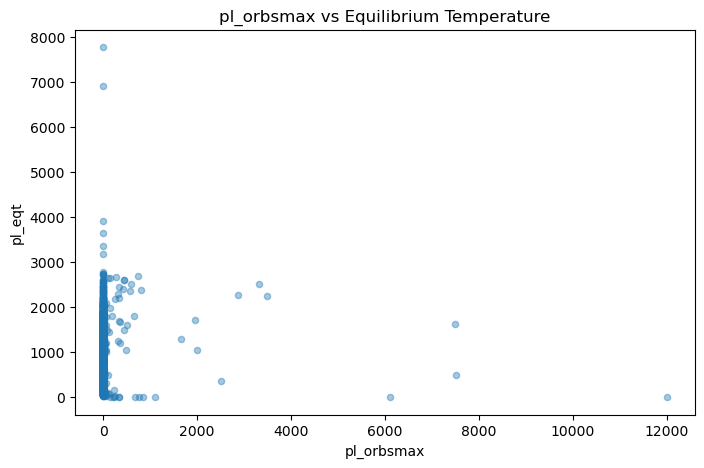

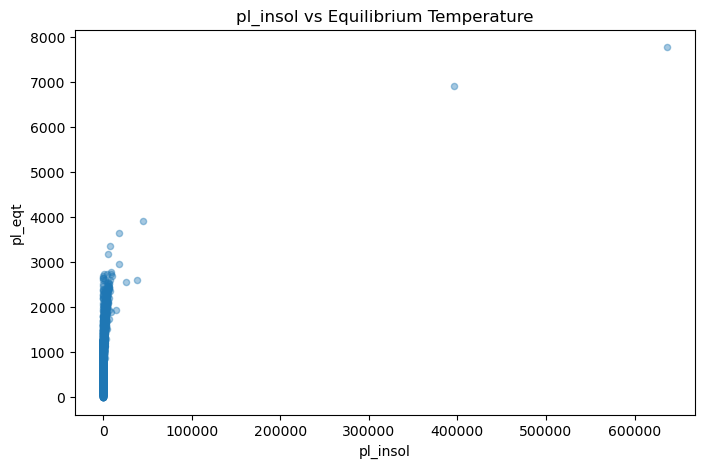

In [52]:
for col in ["st_teff", "pl_orbsmax", "pl_insol"]:
    if col in df.columns:
        plot_data = df[[col, "pl_eqt"]].dropna()
        plot_data.plot(
            kind="scatter",
            x=col,
            y="pl_eqt",
            alpha=0.4,
            title=col + " vs Equilibrium Temperature",
            figsize=(8, 5)
        )


what even are these graphs lol
trying a log scale for better visuals

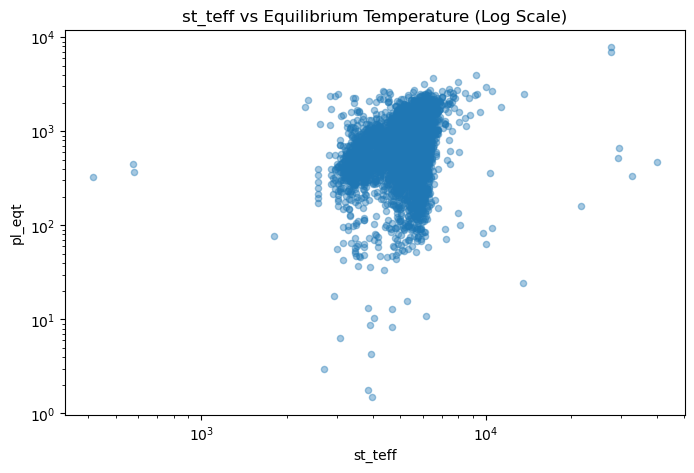

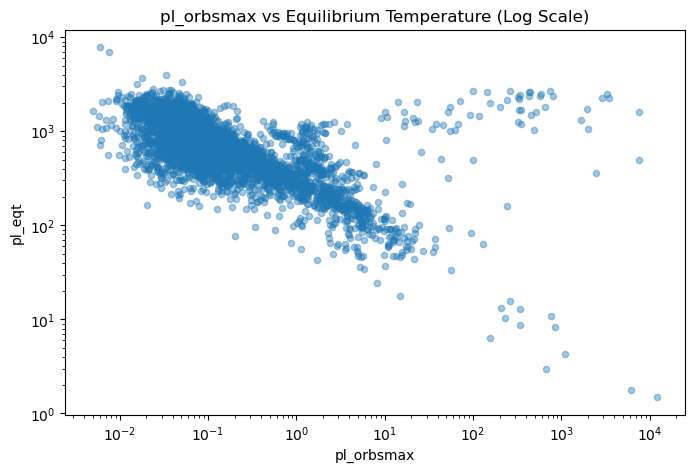

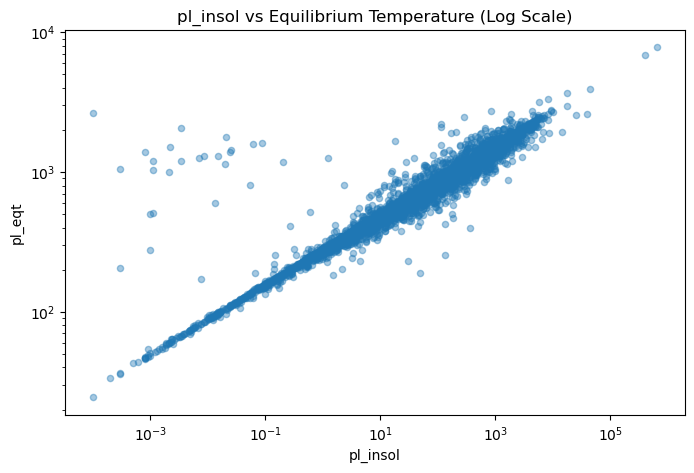

In [65]:
for col in ["st_teff", "pl_orbsmax", "pl_insol"]:
    if col in df.columns:
        plot_data = df[[col, "pl_eqt"]].dropna()
        plot_data = plot_data[(plot_data[col] > 0) & (plot_data["pl_eqt"] > 0)]

        plot_data.plot(
            kind="scatter", x=col, y="pl_eqt",
            logx=True, logy=True,
            alpha=0.4,
            title=col + " vs Equilibrium Temperature (Log Scale)",
            figsize=(8, 5)
        )

In [54]:
#correlation b/w features
features = [
    "st_teff",
    "st_rad",
    "st_mass",
    "pl_orbsmax",
    "pl_insol",
    "pl_rade",
    "pl_bmasse",
    "pl_orbeccen"
]

correlations = df[features].corr()

display(correlations.round(2))

,st_teff,st_rad,st_mass,pl_orbsmax,pl_insol,pl_rade,pl_bmasse,pl_orbeccen
st_teff,1.00,-0.04,0.46,-0.02,0.34,0.16,0.06,-0.00
st_rad,-0.04,1.00,0.45,-0.01,-0.01,0.21,0.33,0.12
st_mass,0.46,0.45,1.00,-0.03,0.00,0.36,0.27,0.12
pl_orbsmax,-0.02,-0.01,-0.03,1.00,-0.00,0.07,0.17,0.20
pl_insol,0.34,-0.01,0.00,-0.00,1.00,0.00,-0.00,-0.09
pl_rade,0.16,0.21,0.36,0.07,0.00,1.00,0.45,0.39
pl_bmasse,0.06,0.33,0.27,0.17,-0.00,0.45,1.00,0.40
pl_orbeccen,-0.00,0.12,0.12,0.20,-0.09,0.39,0.40,1.00


In [83]:
#changing the pl_insol feature after looking at the log log graph to get a linear relationship
df["pl_insol"] = df["pl_insol"] ** 0.25
#can also be done for orbsmax seperately but its being done to calculate physics_temp

#taking help of physics to create a feature made up from non-linear relations expected to have a higher correlation w/ target variable

physics_eqn = (
    (df["st_teff"] > 0) &
    (df["st_rad"] > 0) &
    (df["pl_orbsmax"] > 0)
)

df["physics_temp"] = np.nan

# 1 solar radius is approximately 0.00465047 AU
# estimating equilibrium temperature using the physical relationship T_eq proportional to T_star * sqrt(R_star / a)

df["physics_temp"] = df["st_teff"] * np.sqrt(
    (0.00465047 * df["st_rad"]) /
    (2 * df["pl_orbsmax"])
)

correlation = df["physics_temp"].corr(df["pl_eqt"])

print("Correlation with target (physics temp):", correlation)

correlation = df["pl_insol"].corr(df["pl_eqt"])

print("Correlation with target: (pl_insol)", correlation)

Correlation with target (physics temp): 0.9318242346296078
Correlation with target: (pl_insol) 0.6855436002373385


# EDA FINDINGS - 

1. The raw features most correlated with target feature are the Star Temprature, Stellar Insolation, Stellar Mass and effective orbital radius. They make physical sense as well.
2. The theoretically calculated planet temperature gives the highest correlation with the target variable, which increases the validity of both the observations and the theoretical technique.
3. Features like pl_insol and pl_orbsmax probably have a power law relationship with the target variable, as evidenced by the approximately linear looking log - log plots
4. The distribution of planet temperatures is not symmetric. It is right skewed, with a long tail of planets above 1500K and a few extremely large values, with the most planets being in the 400K - 1000K range.

In [84]:
#test train split

planet_names = df["pl_name"].copy()

feature_columns = df.select_dtypes(include=np.number).columns.tolist()

feature_columns.remove("pl_eqt")

X = df[feature_columns]
y = df["pl_eqt"]

print("Number of input features:", X.shape[1])
print("Number of planets:", X.shape[0])

print("\nInput features:")
print(X.columns.tolist())

np.random.seed(42)

indices = np.random.permutation(len(df))

split_point = int(0.8 * len(df))
train_indices = indices[:split_point]
test_indices = indices[split_point:]

X_train = X.iloc[train_indices].copy()
y_train = y.iloc[train_indices].copy()

X_test = X.iloc[test_indices].copy()
y_test = y.iloc[test_indices].copy()

test_planet_names = planet_names.iloc[test_indices].copy()

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Number of input features: 20
Number of planets: 5911

Input features:
['sy_snum', 'sy_pnum', 'pl_orbper', 'pl_orbsmax', 'pl_rade', 'pl_radj', 'pl_bmasse', 'pl_bmassj', 'pl_orbeccen', 'pl_insol', 'ttv_flag', 'st_teff', 'st_rad', 'st_mass', 'st_met', 'st_logg', 'sy_vmag', 'sy_kmag', 'sy_gaiamag', 'physics_temp']
Training observations: 4728
Testing observations: 1183


I am running a linear regression on 4 datasets - 
1. Including the theoretical temperature and replacing missing fields with the median
2. Including the theoretical temperature and removing rows with missing fields
3. Using just the original features and removing rows with missing fields
4. Using just the original features and replacing missing fields with the median


In [85]:
# version 1: without physics_temp
X_train_raw = X_train.drop(columns=["physics_temp"])
X_test_raw = X_test.drop(columns=["physics_temp"])

# version 2: with physics_temp
X_train_physics = X_train.copy()
X_test_physics = X_test.copy()

In [86]:
# calculate medians using training data only
raw_medians = X_train_raw.median()
physics_medians = X_train_physics.median()

# replace missing values with medians
X_train_raw_median = X_train_raw.fillna(raw_medians)
X_test_raw_median = X_test_raw.fillna(raw_medians)

X_train_physics_median = X_train_physics.fillna(physics_medians)
X_test_physics_median = X_test_physics.fillna(physics_medians)

In [87]:
# remove rows with missing values
X_train_raw_drop = X_train_raw.dropna()
X_test_raw_drop = X_test_raw.dropna()

X_train_physics_drop = X_train_physics.dropna()
X_test_physics_drop = X_test_physics.dropna()

# keep the correct temperatures for the remaining planets
y_train_raw_drop = y_train.loc[X_train_raw_drop.index]
y_test_raw_drop = y_test.loc[X_test_raw_drop.index]

y_train_physics_drop = y_train.loc[X_train_physics_drop.index]
y_test_physics_drop = y_test.loc[X_test_physics_drop.index]


In [88]:
def predict(X, w, b):
    return X @ w + b

def mse(X, y, w, b):
    predictions = predict(X, w, b)
    return np.mean((predictions - y) ** 2)


def train(X, y, alpha=0.001, steps=10000):

    # all weights and the intercept at zero initially
    w = np.zeros(X.shape[1])
    b = 0.0

    history = []

    for i in range(steps):

        error = predict(X, w, b) - y

        dw = (2 / len(y)) * (X.T @ error)
        db = 2 * np.mean(error)

        w = w - alpha * dw
        b = b - alpha * db

        history.append(mse(X, y, w, b))

    return w, b, history

In [89]:
def run_model(name, X_train_df, X_test_df, y_train_data, y_test_data):

    X_train = X_train_df.to_numpy()
    X_test = X_test_df.to_numpy()
    y_train = y_train_data.to_numpy()
    y_test = y_test_data.to_numpy()

    X_mean = X_train.mean(axis=0)
    X_std = X_train.std(axis=0)
    X_std[X_std == 0] = 1

    X_train = (X_train - X_mean) / X_std
    X_test = (X_test - X_mean) / X_std

    y_mean = y_train.mean()
    y_std = y_train.std()
    y_train = (y_train - y_mean) / y_std

    w, b, history = train(X_train, y_train)

    predictions = predict(X_test, w, b) * y_std + y_mean

    error = y_test - predictions

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))
    r2 = 1 - np.sum(error ** 2) / np.sum((y_test - y_test.mean()) ** 2)

    print("\n", name)
    print("MAE:", mae, "K")
    print("RMSE:", rmse, "K")
    print("R^2:", r2)

    return predictions, mae, rmse, r2

# Approach used to implement linear regression-

I chose to implement linear regression using Gradient Descent because I had learnt it in a workshop conducted by IEEE. I wasn't sure whether I wanted to remove rows with null values or replace them with the median, so I thought of trying both and comparing the results. Obviously I defined a function the run the regression instead of seperately doing it for all the datasets. I experimented w/ a few different learning rates and no. of iterations to arrive at the specification here. The number is iterations is a bit more than practically needed as the results didnt change much for 10000 as compared to 5000.

Before running it however, all features were converted to their Z-Scores for standardization such that the mean is 0 and the standard deviation is 1.

I am only maintaining a history of all the changes to all the weights, which can be helpful to better understand the process if needed, like by visualization and plotting. 

In [92]:
print("Evaluation results:\n")

# Model 1: median imputation, without physics_temp
pred1, mae1, rmse1, r21 = run_model(
    "Median - Without Physics", X_train_raw_median, X_test_raw_median, y_train, y_test
)

# Model 2: median imputation, with physics_temp
pred2, mae2, rmse2, r22 = run_model(
    "Median - With Physics", X_train_physics_median, X_test_physics_median, y_train, y_test
)

# Model 3: row deletion, without physics_temp
pred3, mae3, rmse3, r23 = run_model(
    "Row Deletion - Without Physics", X_train_raw_drop, X_test_raw_drop,
    y_train_raw_drop, y_test_raw_drop
)

# Model 4: row deletion, with physics_temp
pred4, mae4, rmse4, r24 = run_model(
    "Row Deletion - With Physics", X_train_physics_drop, X_test_physics_drop,
    y_train_physics_drop, y_test_physics_drop
)


Evaluation results:


 Median - Without Physics
MAE: 272.20537291075476 K
RMSE: 391.0824717618108 K
R^2: 0.4145971480184182

 Median - With Physics
MAE: 90.26278573363986 K
RMSE: 181.75758407288498 K
R^2: 0.8735545477894264

 Row Deletion - Without Physics
MAE: 180.95879269872265 K
RMSE: 249.3996262865198 K
R^2: 0.6787209158470338

 Row Deletion - With Physics
MAE: 49.75234951788739 K
RMSE: 94.9114965708021 K
R^2: 0.953470487833752


Hottest: KOI-55 c , Temp- 6464.122581431636 K
Coldest: Wolf 1061 d , Temp- 83.86226351302992 K


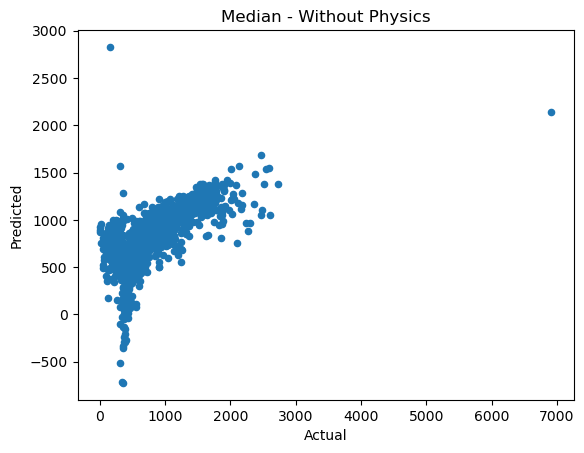

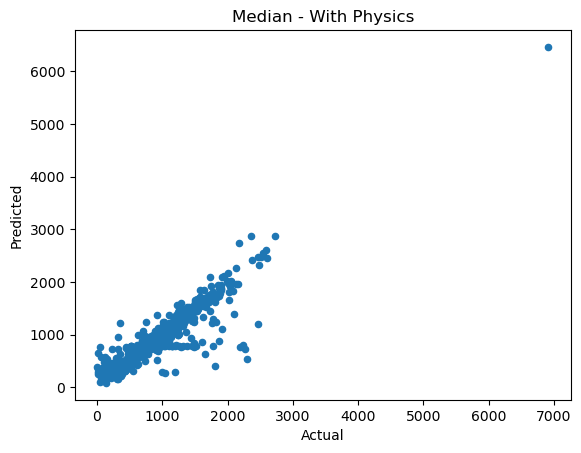

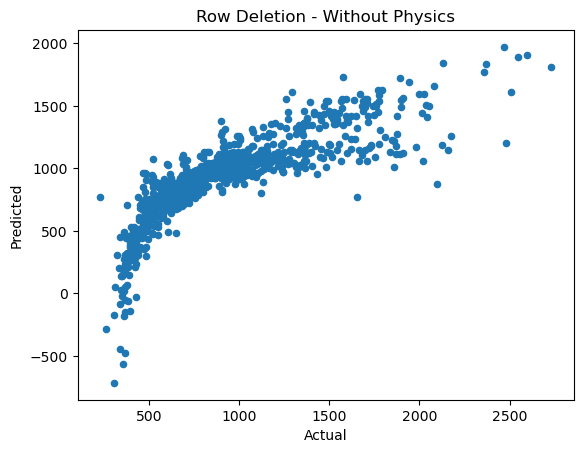

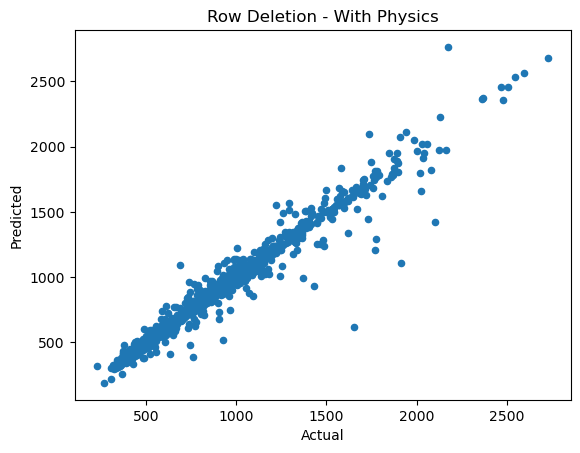

In [93]:
predictions_list = [pred1, pred2, pred3, pred4]

actual_list = [
    y_test,
    y_test,
    y_test_physics_drop,
    y_test_physics_drop
]

names = [
    "Median - Without Physics",
    "Median - With Physics",
    "Row Deletion - Without Physics",
    "Row Deletion - With Physics"
]

for i in range(4):
    plot_data = pd.DataFrame({
        "Actual": actual_list[i].to_numpy(),
        "Predicted": predictions_list[i]
    })

    plot_data.plot(
        kind="scatter",
        x="Actual",
        y="Predicted",
        title=names[i]
    )

temps = pd.Series(pred2, index=test_planet_names)
print("Hottest:", temps.idxmax(), ", Temp-", temps.max(), "K")
print("Coldest:", temps.idxmin(), ", Temp-", temps.min(), "K")

# Final Observations-

As one would expect, including the feature which stands for theoretically calculated temperature drastically changes the effectiveness of the model. Another thing is that the sets where the null values were removed instead of replaced did better, with the errors for the physics temp halving for row removal.

Lower Mean Absolute Error and Root Mean Squared Error are of course better for a model, and an higher R^2 indicates how better a model is as compared to always guessing the average.

Interestingly, the predicted lowest temperature does not match up with the actual lowest.

# Limitations-

1. Since the relationship b/w the target variable and the features is likely non linear (as indicated by the log log graphs and exceptional perfomance of theoretically calculated planet temperature as a feature) a linear regression model isnt best fit for it. A deep learning algorithm like neural networks could have produced a better result.
2. The linear relationship also means that its possible to get unrealistically close to 0K temperature, and models 1 & 3 even reported their coldest temperature to be negative.This problem applies to most linear regression models.
3. Extreme values - firstly the distribution of planet temperatures is quite skewed, and some have extremely hight temperatures which greatly distorts the RMSE (much higher than MAE), decreasing its predictive power for the other temperature ranges.
4. The model performanced much better when I added the theoretically calculated temperature as a feature. If we had no idea beforehand about what relationships are more likely, the raw model based only on the features does much worse.